# The whole pipeline, one model at a time

This notebook walks through the submitted pipeline (**v13**, MD5 `688141c2…`) from the tracking
data to one label per frame. For every model it shows:

1. **where it is trained**: the function in [`possession/training.py`](../possession/training.py), the
   training table, and the model file in [`models/`](../models/);
2. **the target** and **a sample of training rows**;
3. **the inputs**: which matter most (LightGBM gain) and how they push the prediction (exact
   per-feature contributions, TreeSHAP, on Barcelona vs Athletic frames);
4. **validation on the other matches**: every number is *held out*. Each of the 10 external matches is
   scored by models trained on the other 9 (leave one match out);
5. **its output on Barcelona vs Athletic** (BAR-ATH).

Hand-picked constants (evidence weights, temperatures, λ, …) get the same treatment: the value, what it
does and how it was chosen. They are all listed together in section 8.

**No label of BAR-ATH is used anywhere in this notebook**, not even the public 5 minutes. BAR-ATH only
appears as model output and summary statistics.

**Running it.** It needs the match data in `data/` and `train.py`'s cache in `data/training/` (both
are licensed data and not committed). `notebooks/walkthrough.py` computes everything once and
caches it in `data/notebook/` (about 30–60 min). After that the notebook runs in about a minute.

## 0. The pipeline at a glance

| step | what | model file | trained in `possession/training.py` | one training row | target |
|---|---|---|---|---|---|
| 1 | frame features (~110 numbers per frame) | – | – | – | – |
| 2a | **dead head** P(D) | `models/dead_head.txt` | `head_table` → `fit_heads` | a frame of a degraded external copy | ball dead? |
| 2b | **team head** P(H \| alive) | `models/team_head.txt` | `head_table` → `fit_heads` | the same frames, ball alive only | home team has it? |
| 3 | evidence: whistles, Smart Tagging, kick-off | – (fixed rules) | – | – | – |
| 4 | **switch head** P(switch within 0.5 s) | `models/switch_head.txt` | `switch_table` → `fit_switch` | a frame of a degraded copy | possession changes within ±12 frames? |
| 5 | **duration model** (HSMM): best path + candidates | `models/prior.json` | `fit_prior` (`possession/hsmm.py`) | label sequences of the 3 Metrica matches | how long spells last, what follows what |
| 6 | **rescorer** q per candidate, best set kept | `models/rescorer.txt` | `candidate_rows` → `fit_rescorer` | a candidate possession in a held-out decode | its overlap with a real possession |
| 7 | **boundary model** moves each change | `models/boundary.txt` | `boundary_table` → `fit_boundary` | a label change in a held-out decode | frames to the real change |

The code that runs it is [`possession/pipeline.py`](../possession/pipeline.py) (`predict`). The cell
below draws the same thing.

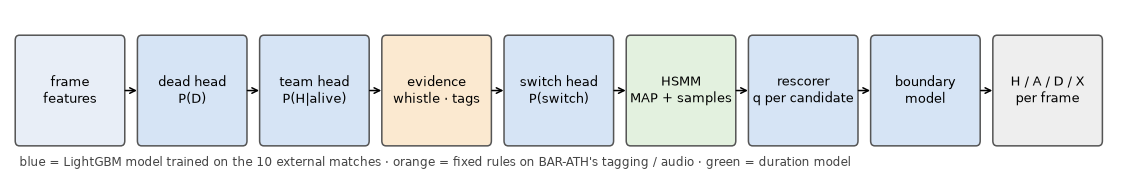

In [1]:
%matplotlib inline
import os, sys, json, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath(".."))
sys.path.insert(0, os.path.abspath("."))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.patches as mp
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss, brier_score_loss

import possession, possession_metrics as pm
from possession import pipeline as pl, training as tr, decoder as dm, hsmm
from possession.whistle import WHISTLE_SPAN, WHISTLES_PER_MATCH, WHISTLE_ALIVE_BEFORE
import walkthrough as wt
from glossary import describe

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
COL = {pm.H: "#2b5fa6", pm.A: "#c0392b", pm.D: "#a0a4a8", pm.X: "#ffffff"}
NAME = {pm.H: "H (Barcelona)", pm.A: "A (Athletic)", pm.D: "D (dead)", pm.X: "X"}
models = pl.load_models()

def flow():
    steps = [("frame\nfeatures", "#e8eef7"), ("dead head\nP(D)", "#d6e4f5"), ("team head\nP(H|alive)", "#d6e4f5"),
             ("evidence\nwhistle · tags", "#fbe9d0"), ("switch head\nP(switch)", "#d6e4f5"),
             ("HSMM\nMAP + samples", "#e3f1df"), ("rescorer\nq per candidate", "#d6e4f5"),
             ("boundary\nmodel", "#d6e4f5"), ("H / A / D / X\nper frame", "#eeeeee")]
    fig, ax = plt.subplots(figsize=(13, 1.9)); ax.axis("off")
    for i, (t, c) in enumerate(steps):
        ax.add_patch(mp.FancyBboxPatch((i * 1.45, 0), 1.2, 1, boxstyle="round,pad=0.05", fc=c, ec="#555"))
        ax.text(i * 1.45 + 0.6, 0.5, t, ha="center", va="center", fontsize=8.5)
        if i:
            ax.annotate("", (i * 1.45 - 0.02, 0.5), (i * 1.45 - 0.23, 0.5), arrowprops=dict(arrowstyle="->"))
    ax.set_xlim(-0.1, len(steps) * 1.45); ax.set_ylim(-0.3, 1.3)
    ax.text(0, -0.25, "blue = LightGBM model trained on the 10 external matches · orange = fixed rules on BAR-ATH's tagging / audio · green = duration model", fontsize=8, color="#444")
    plt.show()
flow()

In [2]:
# The two cached computations (built by `python notebooks/walkthrough.py` if missing)
B = wt.barath()          # every intermediate of the pipeline on BAR-ATH
H = wt.heldout()         # the 10 external matches, every model held out
g, kd = B["graded"], B["known_dead"]
pc = H["per_copy"]

final = B["codes"]["final"]
sub = os.path.join(possession.ROOT, "submission", "paloma.csv")
if os.path.exists(sub):
    same = (pm.label_codes(pm.read_label_csv(sub)) == final).all()
    print("step-by-step labels == submission/paloma.csv:", same)
print("BAR-ATH: {:,} frames, {:,} graded, {:,} known dead (before the 2nd-half kick-off)".format(B["n_frames"], g.sum(), (kd & g).sum()))
print("held-out copies: {} ({} matches x seeds {} x 2 copies)".format(len(pc), pc.match.nunique(), sorted(pc.seed.unique())))

step-by-step labels == submission/paloma.csv: True
BAR-ATH: 199,319 frames, 158,857 graded, 2,934 known dead (before the 2nd-half kick-off)
held-out copies: 60 (10 matches x seeds [np.int64(777), np.int64(888), np.int64(999)] x 2 copies)


In [3]:
# Shared helpers: metrics, ribbons, importance and contribution plots
def fmt_t(f):
    half2 = f >= np.flatnonzero(B["half"] == 2)[0]
    s = (f - (np.flatnonzero(B["half"] == 2)[0] if half2 else np.flatnonzero(B["half"] == 1)[0])) / 25
    return "{}H {:02d}:{:02d}".format(2 if half2 else 1, int(s // 60), int(s % 60))

def binary_metrics(y, p):
    y, p = np.asarray(y, int), np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6)
    hat = p >= 0.5
    tp, fp, fn = (hat & (y == 1)).sum(), (hat & (y == 0)).sum(), (~hat & (y == 1)).sum()
    pr, rc = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return {"frames": len(y), "base rate": y.mean(), "AUC": roc_auc_score(y, p), "AP": average_precision_score(y, p),
            "log loss": log_loss(y, p), "Brier": brier_score_loss(y, p), "accuracy@0.5": (hat == y).mean(),
            "precision@0.5": pr, "recall@0.5": rc, "F1@0.5": 2 * pr * rc / max(pr + rc, 1e-9)}

def by_source(df, ycol, pcol):
    rows = {s: binary_metrics(d[ycol], d[pcol]) for s, d in [("Metrica (3 matches)", df[df.source == "metrica"]),
                                                              ("DFL (7 matches)", df[df.source == "dfl"]), ("all 10", df)]}
    return pd.DataFrame(rows).T

def reliability(ax, y, p, title, bins=10):
    e = np.linspace(0, 1, bins + 1); k = np.clip(np.digitize(p, e) - 1, 0, bins - 1)
    xs = [p[k == i].mean() for i in range(bins) if (k == i).any()]; ys = [y[k == i].mean() for i in range(bins) if (k == i).any()]
    ax.plot([0, 1], [0, 1], ls=":", c="#888"); ax.plot(xs, ys, "o-", c="#2b5fa6")
    ax.set(xlabel="predicted", ylabel="observed share", title=title, xlim=(0, 1), ylim=(0, 1))

def ribbon(ax, codes, a, b, y, h=0.8, label=""):
    c = codes[a:b]; cut = np.flatnonzero(np.diff(c)) + 1
    for s, e in zip(np.r_[0, cut], np.r_[cut, len(c)]):
        ax.add_patch(mp.Rectangle((a + s, y), e - s, h, fc=COL[int(c[s])], ec="none"))
    ax.text(a - (b - a) * 0.005, y + h / 2, label, ha="right", va="center", fontsize=8)

def time_axis(ax, a, b, n=7):
    t = np.linspace(a, b, n).astype(int); ax.set_xticks(t); ax.set_xticklabels([fmt_t(x) for x in t]); ax.set_xlim(a, b)

def legend(ax, loc="upper right"):
    ax.legend(handles=[mp.Patch(color=COL[c], label=NAME[c]) for c in (pm.H, pm.A, pm.D)], loc=loc, fontsize=7, ncol=3, frameon=False)

def gain(booster, k=15):
    s = pd.Series(booster.feature_importance("gain"), booster.feature_name()); return (s / s.sum()).sort_values(ascending=False).head(k)

def features_table(booster, contrib, k=15):
    gi = gain(booster, 1000)
    c = pd.Series(np.abs(contrib["contrib"]).mean(0), contrib["cols"])
    df = pd.DataFrame({"gain share": gi, "mean |contribution| on BAR-ATH (log-odds)": c}).sort_values("gain share", ascending=False).head(k)
    df["kind"] = [describe(x)[0] for x in df.index]; df["meaning"] = [describe(x)[1] for x in df.index]
    return df

def impact_plots(booster, contrib, title, k=12):
    gi = gain(booster, k)[::-1]
    c = pd.Series(np.abs(contrib["contrib"]).mean(0), contrib["cols"]).sort_values().tail(k)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    ax[0].barh(gi.index, gi.values, color="#2b5fa6"); ax[0].set_title(title + ": gain share (training)")
    ax[1].barh(c.index, c.values, color="#7f8c8d"); ax[1].set_title(title + ": mean |contribution| on BAR-ATH (log-odds)")
    plt.tight_layout(); plt.show()
    top = c.index[::-1][:4]
    fig, ax = plt.subplots(1, 4, figsize=(13, 2.8))
    for a, f in zip(ax, top):
        j = contrib["cols"].index(f); x = contrib["X"][:, j]; y = contrib["contrib"][:, j]
        a.scatter(x, y, s=2, alpha=0.25, c="#2b5fa6"); a.axhline(0, c="#888", lw=0.6)
        a.set(title=f, xlabel=describe(f)[0], ylabel="contribution (log-odds)" if a is ax[0] else "")
    plt.suptitle("How the top inputs push " + title + " (one dot = one BAR-ATH frame / row)", y=1.04); plt.tight_layout(); plt.show()
print("ok")

ok


---
## 1. Frame features (input of every head)

[`possession/features.py`](../possession/features.py) and [`possession/interact.py`](../possession/interact.py)
turn the tracking into one row per frame (no player identities are needed; `h_*` = home team,
`a_*` = away team, coordinates flipped so +x always points at the away goal):

| group | examples | idea |
|---|---|---|
| team shape | `h_cx`, `a_spread_y`, `h_line`, `cx_gap` | the team with the ball pushes up and spreads out |
| movement | `speed_all`, `frac_slow`, `speed_change_1s` | play stops → players walk |
| ball | `ball_seen`, `bx`, `ball_speed`, `ball_out` | where the ball is (missing on 41% of graded frames) |
| who is near the ball | `d_margin`, `ctrl` (≤ 1.0 m and nearest), `near_team`, `last_ctrl`, `next_ctrl` | the core possession signal |
| ball-gap context | `t_since_seen`, `gap_len`, `last_bx`, `next_bx` | what happened around a tracking gap |
| windows | `*_c1`, `*_c3`, `*_c10`, `*_past3`, `*_fut3` | the same signals smoothed over ±1/3/10 s, or only before/after |
| interactions (`ix_*`) | `ix_proj05_margin`, `ix_mark_diff`, `ix_trend_h_cx` | who reaches the ball's position in 0.5 s, marking, 2-s trends |

The dead and team heads read the same **108 columns**. 8 more interaction columns were dropped because
their distribution on BAR-ATH is unlike any training match (`training.SHIFTED`, inputs compared only,
never labels).

In [4]:
cols = models["dead"].feature_name()
pd.DataFrame([(c,) + describe(c) for c in cols], columns=["column", "kind", "meaning"]).set_index("column").head(40)

,kind,meaning
column,,
h_n,count,home players tracked in this frame
h_cx,m,"home centroid x (home-attack coordinates, 0 = ..."
h_spread,m,home team spread: RMS distance of home players...
h_spread_x,m,home spread along the pitch (std of x)
h_spread_y,m,home spread across the pitch (std of y)
h_vfwd,m/s,home players' mean forward velocity (towards t...
h_speed,m/s,home players' mean speed
a_n,count,away players tracked in this frame
a_cx,m,"away centroid x (home-attack coordinates, 0 = ..."


### Where the training rows come from

The 10 external matches have clean tracking; BAR-ATH's is automatic and noisy. So each match is
**degraded** to look like BAR-ATH (ball gaps, broken player tracks, noise: `possession/degrade.py`, using
only summary statistics of BAR-ATH's tracking) and copied 3× (Metrica) or 2× (DFL), each also with
home and away swapped (so "home usually has the ball" can't be learned). Every 5th (Metrica) / 10th
(DFL) labelled frame is kept. The tables are cached in `data/training/r1.0/head_table_<source>_<match>.pkl`.

In [5]:
sizes, tabs = [], {}
for k in tr.MATCHES:
    X, y = pd.read_pickle(os.path.join(possession.DATA_DIR, "training", "r1.0", "head_table_{}_{}.pkl".format(*k)))
    tabs[k] = (X, y)
    sizes.append({"source": k[0], "match": k[1], "rows": len(y), "H": (y == pm.H).mean(), "A": (y == pm.A).mean(), "D": (y == pm.D).mean()})
sizes = pd.DataFrame(sizes)
print("total training rows: {:,}".format(sizes.rows.sum()))
sizes.style.format({"rows": "{:,}", "H": "{:.1%}", "A": "{:.1%}", "D": "{:.1%}"})

total training rows: 910,930


,source,match,rows,H,A,D
0,metrica,1,"170,489",32.0%,32.0%,35.9%
1,metrica,2,"168,137",34.1%,34.1%,31.7%
2,metrica,3,"171,238",36.6%,36.6%,26.8%
3,dfl,J03WMX,"58,388",29.2%,29.3%,41.5%
4,dfl,J03WN1,"56,625",24.2%,24.1%,51.7%
5,dfl,J03WOH,"54,888",26.2%,26.2%,47.6%
6,dfl,J03WOY,"57,016",26.8%,26.7%,46.5%
7,dfl,J03WPY,"58,485",27.9%,27.8%,44.3%
8,dfl,J03WQQ,"56,940",29.7%,29.6%,40.7%
9,dfl,J03WR9,"58,724",29.0%,29.1%,41.9%


---
## 2a. Dead head: P(ball dead)

| | |
|---|---|
| model file | [`models/dead_head.txt`](../models/dead_head.txt) (LightGBM text format) |
| trained by | `training.fit_heads` on all 10 head tables (`training.head_table`) |
| target | `y == D` (1 if the ball is dead) |
| rows | every row of the head tables (≈ 1.6 M, above) |
| parameters | `training.HEAD_PARAMS`: binary, lr 0.05, 31 leaves, ≥ 200 rows per leaf; **1,500 trees** (`HEAD_ROUNDS`) |

**Why 1,500 trees (the v13 change).** 300 was a default from an early version. Held-out log loss on
the DFL matches (labels of the same kind as the ground truth) keeps falling until 800–1,800 trees; at
the decoded-possession stage 1,500 trees gave +0.013 spellF1 over 300, on all 10 held-out matches
and again on fresh copies (seed 555).

In [6]:
X0, y0 = tabs[("dfl", "J03WMX")]
rng = np.random.default_rng(1)
pick = np.r_[rng.choice(np.flatnonzero(y0 != pm.D), 3, False), rng.choice(np.flatnonzero(y0 == pm.D), 3, False)]
top = gain(models["dead"], 10).index
sample = X0.iloc[pick][list(top)].copy()
sample.insert(0, "target: dead?", (y0[pick] == pm.D).astype(int))
sample["P(D) of the model"] = models["dead"].predict(X0.iloc[pick][cols])
print("Six training rows of DFL match J03WMX (open data, CC BY 4.0), its 10 highest-gain columns:")
sample.round(2)

Six training rows of DFL match J03WMX (open data, CC BY 4.0), its 10 highest-gain columns:


,target: dead?,speed_all_fut3,speed_all_c3,ball_speed_c3,ball_speed_c1,ball_speed_c10,ball_speed,t_since_ctrl,ball_out_c1,speed_all_c10,ball_out,P(D) of the model
29682,0,4.77,4.44,NaN,NaN,NaN,NaN,12.96,NaN,3.66,NaN,0.0
27247,0,2.65,2.29,6.06,7.74,6.70,5.28,0.68,0.00,2.07,0.00,0.0
43999,0,2.27,2.20,5.81,8.96,7.32,3.70,1.20,0.00,2.35,0.00,0.0
49784,1,0.67,0.65,0.31,0.27,0.33,0.26,37.12,0.38,0.70,0.38,1.0
56150,1,1.40,1.41,NaN,NaN,NaN,NaN,60.00,NaN,1.70,NaN,1.0
10107,1,0.45,0.48,NaN,NaN,NaN,NaN,28.32,NaN,0.59,NaN,1.0


### Inputs: what matters and how it pushes P(D)

,gain share,mean |contribution| on BAR-ATH (log-odds),kind,meaning
speed_all_fut3,0.198,1.033,m/s,mean speed of all tracked players (play stops ...
speed_all_c3,0.189,0.290,m/s,mean speed of all tracked players (play stops ...
ball_speed_c3,0.075,0.530,m/s,"ball speed, 5-frame smoothed — mean over ±3 s"
ball_speed_c1,0.057,0.403,m/s,"ball speed, 5-frame smoothed — mean over ±1 s"
ball_speed_c10,0.046,0.635,m/s,"ball speed, 5-frame smoothed — mean over ±10 s"
ball_speed,0.045,0.972,m/s,"ball speed, 5-frame smoothed"
t_since_ctrl,0.024,0.382,s,seconds since a player last controlled the ball
ball_out_c1,0.022,0.142,m,how far the ball is outside the pitch lines (0...
speed_all_c10,0.022,0.212,m/s,mean speed of all tracked players (play stops ...
ball_out,0.018,0.066,m,how far the ball is outside the pitch lines (0...


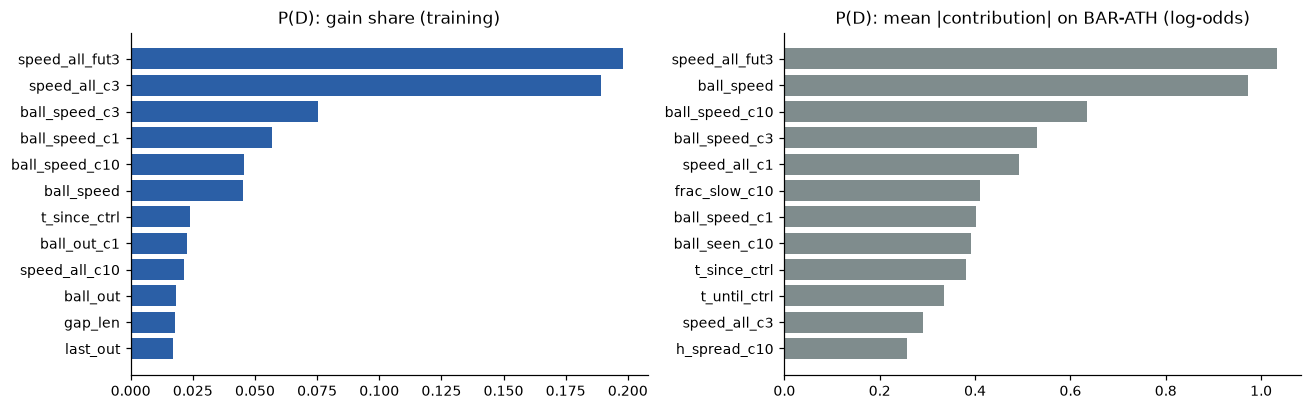

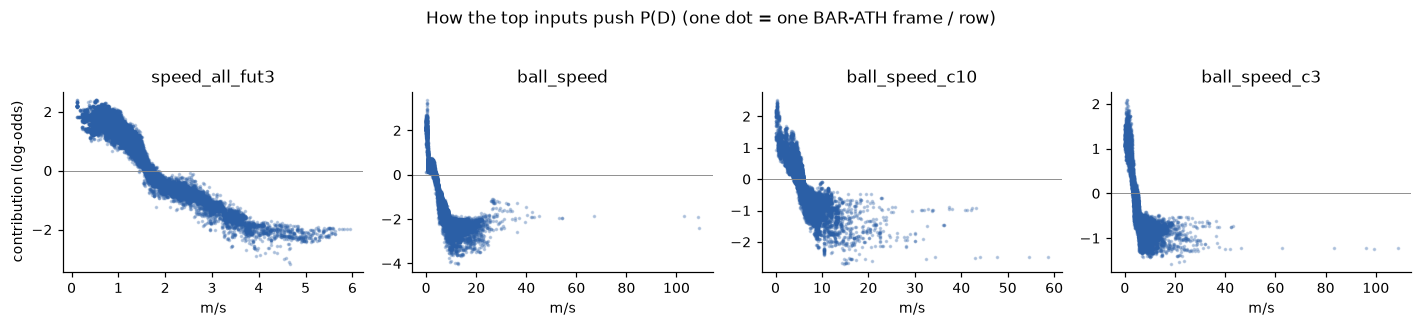

In [7]:
display(features_table(models["dead"], B["contrib"]["dead"]))
impact_plots(models["dead"], B["contrib"]["dead"], "P(D)")

**Reading it.** Slow play (`speed_all*`, `frac_slow*`) and a ball that is missing or out (`ball_seen*`,
`ball_out*`, `t_since_seen`) mean a stoppage. The contribution plots show the direction: low player
speed pushes towards D, a ball seen moving fast pushes towards alive.

### Validation on the other matches (held out)

Each external match was scored by a dead head trained on the other 9 (`training.heldout_copies`:
3 seeds × 2 fresh degraded copies per match). Every 5th labelled frame:

,frames,base rate,AUC,AP,log loss,Brier,accuracy@0.5,precision@0.5,recall@0.5,F1@0.5
Metrica (3 matches),5.099e+05,0.315,0.972,0.920,0.303,0.068,0.916,0.815,0.95,0.877
DFL (7 matches),1.203e+06,0.448,0.996,0.995,0.087,0.025,0.966,0.974,0.95,0.962
all 10,1.713e+06,0.409,0.987,0.976,0.151,0.038,0.951,0.932,0.95,0.941


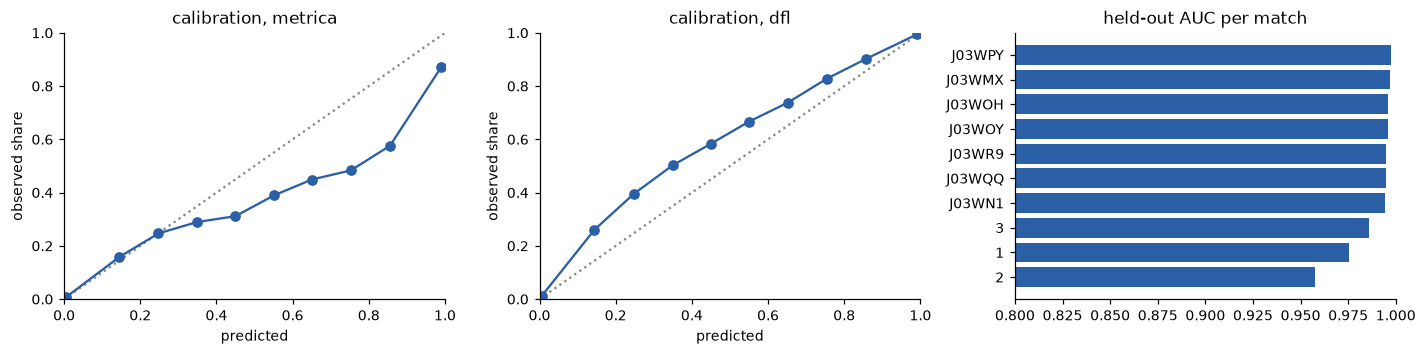

In [8]:
hd = H["heads"].assign(dead=lambda d: (d.y == pm.D).astype(int))
display(by_source(hd, "dead", "p_dead"))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
for a, s in zip(ax[:2], ("metrica", "dfl")):
    d = hd[hd.source == s]; reliability(a, d.dead.to_numpy(), d.p_dead.to_numpy(), "calibration, " + s)
auc = hd.groupby("match").apply(lambda d: roc_auc_score(d.dead, d.p_dead)).sort_values()
ax[2].barh(auc.index, auc.values, color="#2b5fa6"); ax[2].set_xlim(0.8, 1); ax[2].set_title("held-out AUC per match")
plt.tight_layout(); plt.show()

Metrica's labels come from events (when the ball goes dead is a judgement); DFL's are tracking flags
like the ground truth, so DFL is the closer reference. On Metrica the 1,500-tree dead head is
**over-confident** (worse log loss than 300 trees) but it still ranks frames well, and ranking near
boundaries is what the decoder uses.

### Output on Barcelona vs Athletic

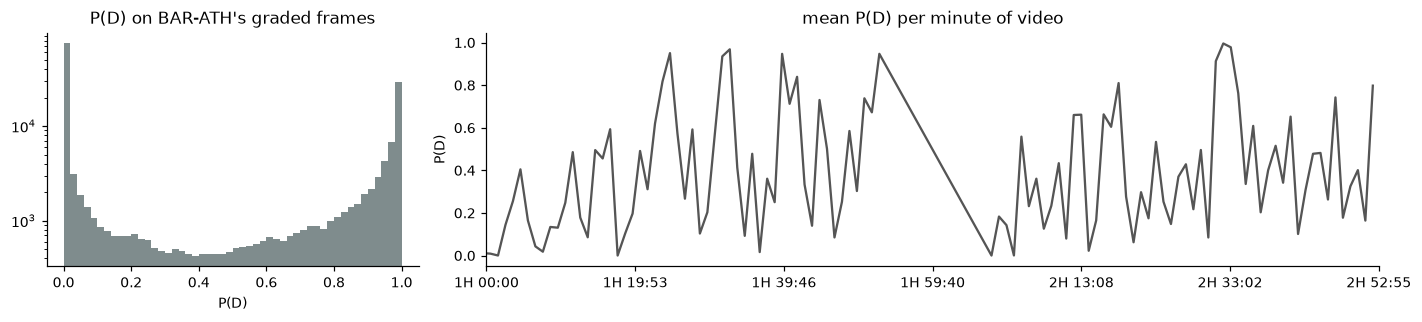

graded frames with P(D) > 0.5: 40.2% (DFL ground truth: 41-52% D)


In [9]:
pdd = B["p_dead"]
fig, ax = plt.subplots(1, 2, figsize=(13, 3), gridspec_kw={"width_ratios": [1, 2.4]})
ax[0].hist(pdd[g & ~kd], bins=50, color="#7f8c8d"); ax[0].set(title="P(D) on BAR-ATH's graded frames", xlabel="P(D)", yscale="log")
# per-minute mean P(D) across the match
mins = np.flatnonzero(g & ~kd)
mm = pd.Series(pdd[mins]).groupby(mins // 1500).mean()
ax[1].plot(mm.index * 1500, mm.values, c="#555"); ax[1].set(title="mean P(D) per minute of video", ylabel="P(D)")
time_axis(ax[1], mins[0], mins[-1])
plt.tight_layout(); plt.show()
print("graded frames with P(D) > 0.5: {:.1%} (DFL ground truth: 41-52% D)".format((pdd[g & ~kd] > 0.5).mean()))

---
## 2b. Team head: P(home has the ball | ball alive)

| | |
|---|---|
| model file | [`models/team_head.txt`](../models/team_head.txt) |
| trained by | `training.fit_heads`, same tables, **only rows where the ball is alive** |
| target | `y == H` (1 if the home team has it) |
| parameters | the same as the dead head, 1,500 trees |

The two heads combine into per-frame log-probabilities of H, A and D (`pipeline.head_emission`):
`log P(H) = log(1 − P(D)) + log P(H|alive)`, `log P(A) = log(1 − P(D)) + log(1 − P(H|alive))`, `log P(D)`.
Because every copy is also used with home/away swapped, the team head is symmetric: it can't
learn a home bias.

In [10]:
alive = np.flatnonzero(y0 != pm.D)
pick = np.r_[rng.choice(alive[y0[alive] == pm.H], 3, False), rng.choice(alive[y0[alive] == pm.A], 3, False)]
top = gain(models["team"], 10).index
sample = X0.iloc[pick][list(top)].copy()
sample.insert(0, "target: home?", (y0[pick] == pm.H).astype(int))
sample["P(H|alive) of the model"] = models["team"].predict(X0.iloc[pick][cols])
sample.round(2)

,target: home?,last_ctrl,ctrl_c3,ctrl_past3,h_spread_y,a_spread_y,ctrl_c1,speed_all_c10,speed_change_1s,a_vfwd,h_vfwd_c1,P(H|alive) of the model
23324,1,-1.0,NaN,NaN,12.35,9.85,NaN,2.10,0.19,1.99,2.59,0.81
49409,1,1.0,NaN,NaN,17.12,13.32,NaN,2.10,-0.51,-0.79,-0.63,0.98
16050,1,1.0,0.47,0.51,12.02,11.31,0.57,2.21,0.16,-1.72,-0.88,1.00
35092,0,-1.0,-0.28,-0.32,10.33,10.50,-0.63,2.32,0.16,-1.05,-0.49,0.01
30740,0,-1.0,0.00,NaN,10.49,13.54,NaN,2.68,0.15,0.15,0.48,0.04
22897,0,1.0,0.11,-0.04,10.58,5.94,0.20,3.43,0.13,-3.34,-2.59,0.09


,gain share,mean |contribution| on BAR-ATH (log-odds),kind,meaning
last_ctrl,0.206,0.822,−1 / +1,team of the last player in control (ctrl ≠ 0) ...
ctrl_c3,0.149,0.351,−1 / 0 / +1,"+1 a home player within 1.0 m and closest, −1 ..."
ctrl_past3,0.103,0.283,−1 / 0 / +1,"+1 a home player within 1.0 m and closest, −1 ..."
h_spread_y,0.063,0.614,m,home spread across the pitch (std of y)
a_spread_y,0.062,0.473,m,away spread across the pitch (std of y)
ctrl_c1,0.036,0.233,−1 / 0 / +1,"+1 a home player within 1.0 m and closest, −1 ..."
speed_all_c10,0.017,0.105,m/s,mean speed of all tracked players (play stops ...
speed_change_1s,0.016,0.074,m/s,speed_all now minus its mean over the last 1 s...
a_vfwd,0.015,0.151,m/s,away players' mean forward velocity (towards t...
h_vfwd_c1,0.012,0.189,m/s,home players' mean forward velocity (towards t...


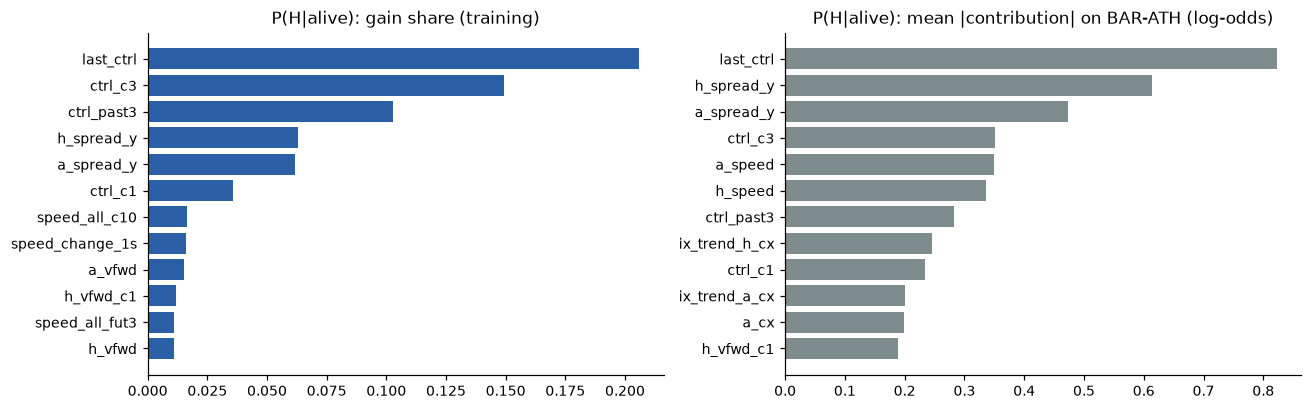

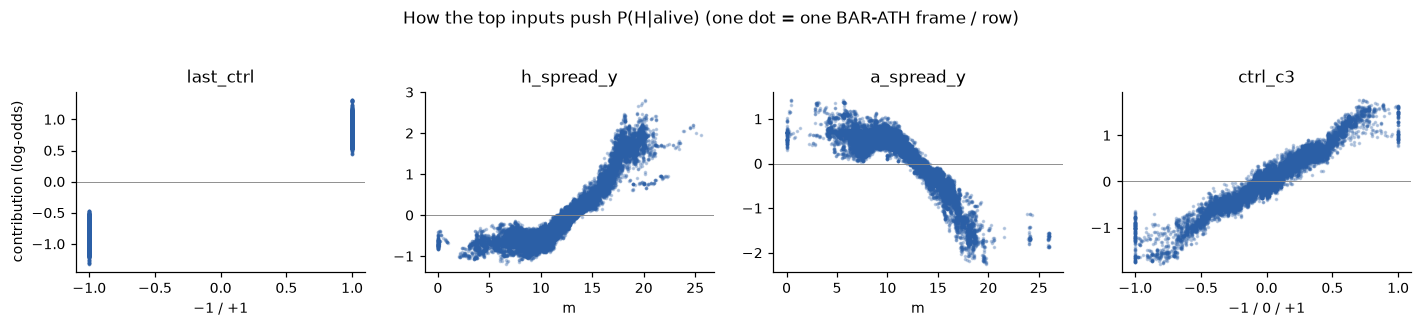

In [11]:
display(features_table(models["team"], B["contrib"]["team"]))
impact_plots(models["team"], B["contrib"]["team"], "P(H|alive)")

**Reading it.** Who was last in control and is nearest the ball, smoothed over a few seconds
(`ctrl_c*`, `last_ctrl`, `d_margin_c*`), carries most of it. Team shape (`cx_gap`, spreads) helps when
the ball is missing: the team in possession pushes up and spreads out.

,frames,base rate,AUC,AP,log loss,Brier,accuracy@0.5,precision@0.5,recall@0.5,F1@0.5
Metrica (3 matches),3.494e+05,0.529,0.966,0.963,0.246,0.074,0.895,0.915,0.882,0.898
DFL (7 matches),6.637e+05,0.532,0.964,0.968,0.247,0.075,0.897,0.907,0.898,0.903
all 10,1.013e+06,0.531,0.964,0.966,0.247,0.075,0.896,0.910,0.892,0.901


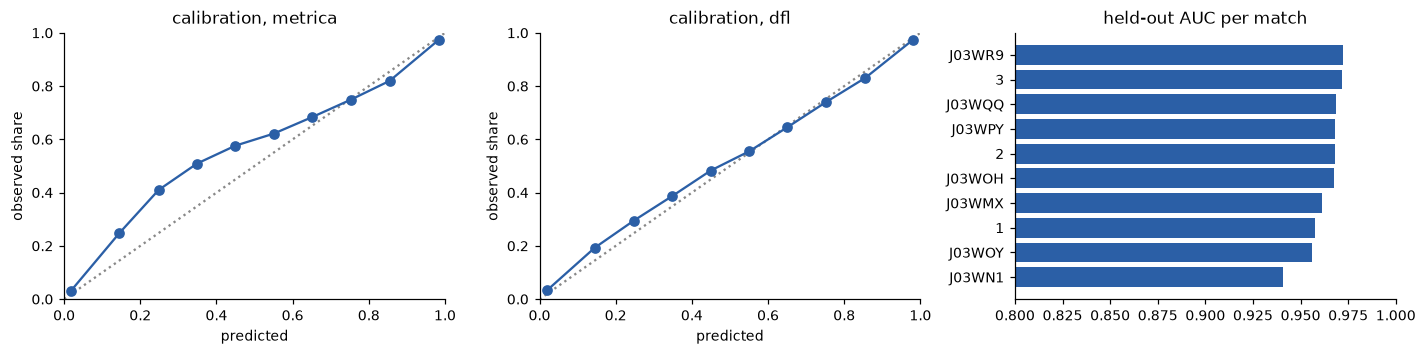

per-frame argmax of the two heads, held out: accuracy 0.900, macro F1 0.894 (H 0.872, A 0.870, D 0.942)


In [12]:
ha = hd[hd.y != pm.D].assign(home=lambda d: (d.y == pm.H).astype(int))
display(by_source(ha, "home", "p_home"))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
for a, s in zip(ax[:2], ("metrica", "dfl")):
    d = ha[ha.source == s]; reliability(a, d.home.to_numpy(), d.p_home.to_numpy(), "calibration, " + s)
auc = ha.groupby("match").apply(lambda d: roc_auc_score(d.home, d.p_home)).sort_values()
ax[2].barh(auc.index, auc.values, color="#2b5fa6"); ax[2].set_xlim(0.8, 1); ax[2].set_title("held-out AUC per match")
plt.tight_layout(); plt.show()
# the argmax of the combined emission, per frame
lab = H["heads"].y.to_numpy(); e3 = np.column_stack([(1 - H["heads"].p_dead) * H["heads"].p_home, (1 - H["heads"].p_dead) * (1 - H["heads"].p_home), H["heads"].p_dead])
am = e3.argmax(1)
f1 = [2 * ((am == c) & (lab == c)).sum() / ((am == c).sum() + (lab == c).sum()) for c in (pm.H, pm.A, pm.D)]
print("per-frame argmax of the two heads, held out: accuracy {:.3f}, macro F1 {:.3f} (H {:.3f}, A {:.3f}, D {:.3f})".format((am == lab).mean(), np.mean(f1), *f1))

### Output on Barcelona vs Athletic: one minute of both heads

window: 1H 21:00 -> 1H 22:30 (90 s)


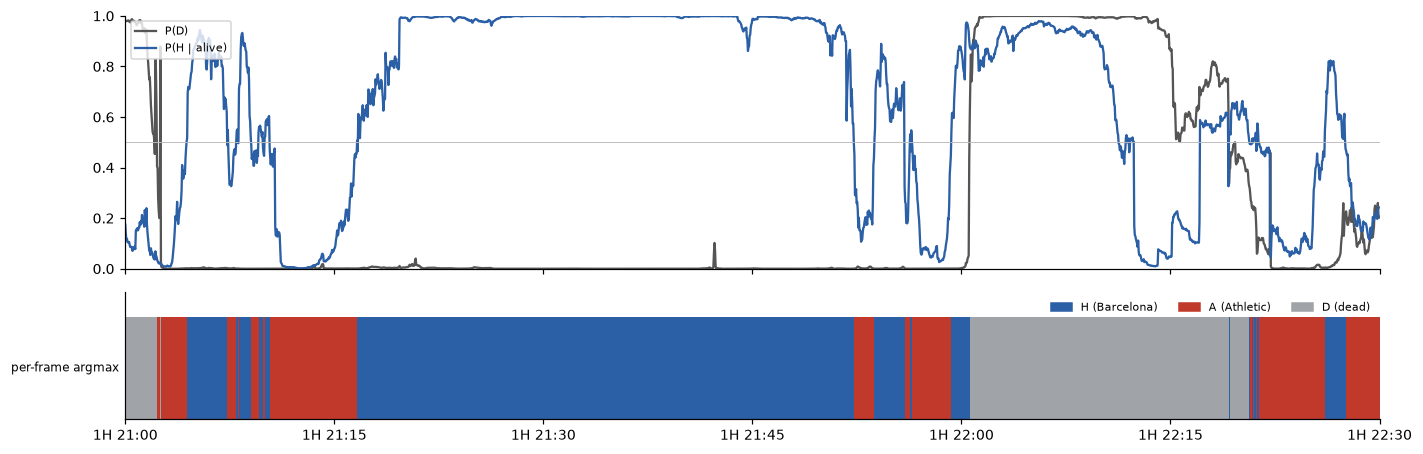

per-frame argmax alone: 12.0 possessions/min (DFL truth ~4.6/min, most of the extra are flicker)


In [13]:
# the minute with most final possessions in the first half (chosen from the predictions only)
runs = pm.valid_runs(np.where(g, pm.D, pm.X))
fsp = dm.team_spells(dm.code_segments(final, runs))
h1 = np.flatnonzero(B["half"] == 1)
starts = np.arange(h1[0] + 1500 * 5, h1[-1] - 3000, 750)
W0 = int(starts[np.argmax([((fsp[:, 0] >= s) & (fsp[:, 1] <= s + 2250)).sum() for s in starts])]); W1 = W0 + 2250
print("window:", fmt_t(W0), "->", fmt_t(W1), "(90 s)")
fig, ax = plt.subplots(2, 1, figsize=(13, 4.2), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
x = np.arange(W0, W1)
ax[0].plot(x, B["p_dead"][W0:W1], c="#555", label="P(D)"); ax[0].plot(x, B["p_home"][W0:W1], c=COL[pm.H], label="P(H | alive)")
ax[0].axhline(0.5, c="#bbb", lw=0.6); ax[0].legend(fontsize=7, loc="upper left"); ax[0].set_ylim(0, 1)
ribbon(ax[1], B["codes"]["argmax"], W0, W1, 0, label="per-frame argmax"); ax[1].set_ylim(0, 1); ax[1].set_yticks([])
time_axis(ax[1], W0, W1); legend(ax[1]); plt.tight_layout(); plt.show()
print("per-frame argmax alone: {:.1f} possessions/min (DFL truth ~4.6/min, most of the extra are flicker)".format(
    len(dm.team_spells(dm.code_segments(B['codes']['argmax'], runs))) / (g.sum() / 1500)))

---
## 3. Extra evidence on BAR-ATH: whistles, Smart Tagging, kick-off

Three fixed rules add **log-odds towards D** to the emission (`pipeline.match_emission`). They are the
only match-specific inputs besides tracking, and none is learned from BAR-ATH labels.

| evidence | where it applies | amount per frame (log-odds to D) | how the amount was chosen |
|---|---|---|---|
| **stop whistle** (`whistle.add_whistle_evidence`) | the 75 frames (3 s) after a whistle heard while the dead head leans "in play" (mean P(D) < 0.5 over the 2 s before) | `dead_insert_cost(prior, 75) × T_dead / 75` (computed below) | derived, not tuned: the 75 frames together pay exactly what the duration model charges for inserting a 3-s stoppage into a 10-s possession. A whistle settles an unsure stretch but can't overrule a confident model. |
| **set-piece tag** (`SET_PIECE_WEIGHT`) | first 2 s of a Smart Tagging set-piece tag | **+3.0** | a set piece is a restart, so the ball was dead just before. 50 frames × 3 = 150 log-odds (18.8 after the dead temperature 8) outweighs the 12.8 the prior charges for inserting a 3-s stoppage, so the tag is near-certain evidence. |
| **untagged gap** (`TAG_GAP_WEIGHT`) | frames no Smart Tagging phase covers (mostly stoppages) | **+0.6** | half the log-likelihood ratio of "untagged → dead" measured against rule-based ball-out labels (no hand labels); half because the heads already see part of the same signal. |
| **known dead** (`utils.known_dead`) | graded frames before the 2nd-half kick-off (organiser-published: kick-off at frame 113742) | H and A set to −10⁴ (forced D) | a published fact, not a model |

**The whistle detector** ([`possession/whistle.py`](../possession/whistle.py)) has no training labels
either: the whistles at the tagged kick-offs give a template of this referee's whistle, frames are
scored by spectral similarity to it, and the threshold is set so the match yields **34 whistle events**
(the mean number of whistled events per DFL match, from the DFL event data).

In [14]:
prior = models["prior"]
cost = hsmm.dead_insert_cost(prior, WHISTLE_SPAN)
print("dead_insert_cost(prior, {} frames) = {:.1f} (tempered units)".format(WHISTLE_SPAN, cost))
print("whistle weight = {:.1f} x T_dead {} / {} frames = {:.3f} log-odds per frame (pipeline: {:.3f})".format(
    cost, pl.TEMPERATURE[1], WHISTLE_SPAN, cost * pl.TEMPERATURE[1] / WHISTLE_SPAN, B["whistle_weight"]))
print("set piece: 50 frames x {} = {:.0f} raw = {:.1f} tempered, vs {:.1f} to insert a 3-s stoppage".format(
    pl.SET_PIECE_WEIGHT, 50 * pl.SET_PIECE_WEIGHT, 50 * pl.SET_PIECE_WEIGHT / pl.TEMPERATURE[1], cost))
add = (B["e"] - B["raw"])[:, 2]
ev = pd.DataFrame({
    "events": [len(B["whistles"]), int(np.sum(np.diff(np.r_[0, B["set_piece"].astype(int)]) == 1)), "", ""],
    "frames touched": [int(sum(min(WHISTLE_SPAN, B["n_frames"] - t) for t in B["whistles"])), int(B["set_piece"].sum()), int((B["tag_gap"] > 0).sum()), int((kd & g).sum())],
    "log-odds per frame": [B["whistle_weight"], pl.SET_PIECE_WEIGHT, pl.TAG_GAP_WEIGHT, "forced"]},
    index=["stop whistles", "set-piece starts", "untagged frames", "known dead"])
display(ev)
print("graded frames with any added evidence: {:.1%}".format(((add > 0) & g).mean() / g.mean()))

dead_insert_cost(prior, 75 frames) = 12.8 (tempered units)
whistle weight = 12.8 x T_dead 8 / 75 frames = 1.367 log-odds per frame (pipeline: 1.367)
set piece: 50 frames x 3.0 = 150 raw = 18.8 tempered, vs 12.8 to insert a 3-s stoppage


,events,frames touched,log-odds per frame
stop whistles,18,1350,1.367
set-piece starts,59,2950,3.0
untagged frames,,69938,0.6
known dead,,2934,forced


graded frames with any added evidence: 25.9%


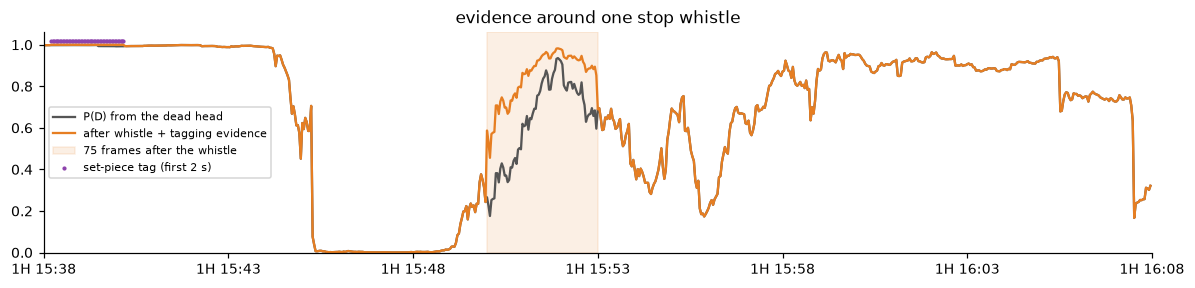

In [15]:
# A stretch with a stop whistle: P(D) before and after the evidence
t = B["whistles"][np.argmin(np.abs(B["whistles"] - (W0 + 1125)))]
a, b = t - 300, t + 450
x = np.arange(a, b)
pd_raw = np.exp(B["raw"][a:b, 2]); pd_ev = 1 / (1 + np.exp(-(B["e"][a:b, 2] - np.logaddexp(B["e"][a:b, 0], B["e"][a:b, 1]))))
fig, ax = plt.subplots(figsize=(13, 2.6))
ax.plot(x, pd_raw, c="#555", label="P(D) from the dead head"); ax.plot(x, pd_ev, c="#e67e22", label="after whistle + tagging evidence")
ax.axvspan(t, t + WHISTLE_SPAN, color="#e67e22", alpha=0.12, label="75 frames after the whistle")
sp = np.flatnonzero(B["set_piece"][a:b]);
if len(sp): ax.scatter(a + sp, np.full(len(sp), 1.02), s=3, c="#8e44ad", label="set-piece tag (first 2 s)")
ax.set_ylim(0, 1.06); ax.legend(fontsize=7, loc="center left"); time_axis(ax, a, b); ax.set_title("evidence around one stop whistle")
plt.show()

---
## 4. The duration model (HSMM): best path and candidate possessions

Per-frame argmax flickers. The decoder is a **hidden semi-Markov model** over blocks of 5 frames
(0.2 s): it knows how long possessions and stoppages last, and what follows what.

**States.** `H`, `A`, `D after H`, `D after A` (a stoppage remembers who had the ball, so the restart
can go back to the same team). **Durations.** Each state carries its age; at every block the spell
ends with probability **h(age)**, the hazard, or goes on with 1 − h(age). **Transitions** when a spell
ends are fitted from the 3 Metrica matches' label sequences (`hsmm.fit_prior` → `models/prior.json`):

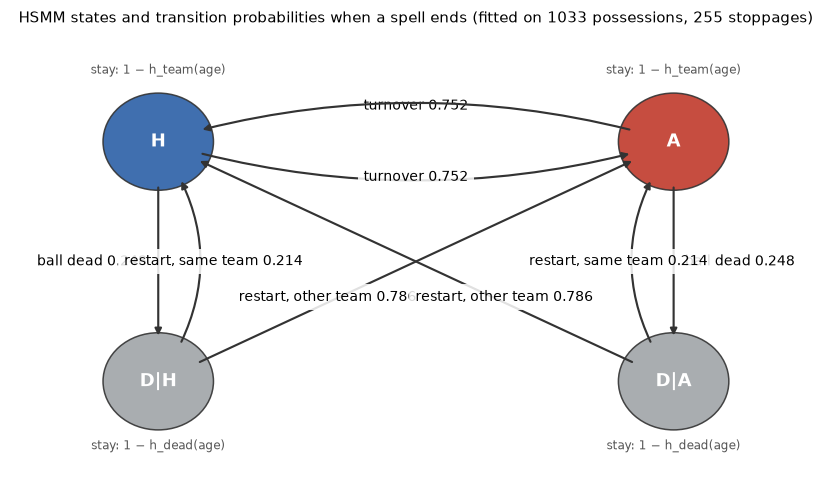

In [16]:
ptd, prs = prior["p_team_to_dead"], prior["p_restart_same"]
fig, ax = plt.subplots(figsize=(9.5, 5.2)); ax.axis("off"); ax.set_xlim(-0.5, 10.5); ax.set_ylim(-0.6, 6.2)
pos = {"H": (1.5, 4.5), "A": (8.5, 4.5), "D|H": (1.5, 0.8), "D|A": (8.5, 0.8)}
fc = {"H": COL[pm.H], "A": COL[pm.A], "D|H": COL[pm.D], "D|A": COL[pm.D]}
for k, (x, y) in pos.items():
    ax.add_patch(mp.Circle((x, y), 0.75, fc=fc[k], ec="#333", alpha=0.9)); ax.text(x, y, k, ha="center", va="center", color="white", fontsize=12, weight="bold")
def arrow(a, b, txt, rad=0.0, off=(0, 0)):
    (x0, y0), (x1, y1) = pos[a], pos[b]
    ax.annotate("", (x1, y1), (x0, y0), arrowprops=dict(arrowstyle="-|>", lw=1.4, color="#333", shrinkA=30, shrinkB=30, connectionstyle="arc3,rad={}".format(rad)))
    ax.text((x0 + x1) / 2 + off[0], (y0 + y1) / 2 + off[1], txt, ha="center", va="center", fontsize=9, bbox=dict(fc="white", ec="none", alpha=0.85))
arrow("H", "A", "turnover {:.3f}".format(1 - ptd), 0.15, (0, 0.55)); arrow("A", "H", "turnover {:.3f}".format(1 - ptd), 0.15, (0, -0.55))
arrow("H", "D|H", "ball dead {:.3f}".format(ptd), 0.0, (-0.9, 0)); arrow("A", "D|A", "ball dead {:.3f}".format(ptd), 0.0, (0.9, 0))
arrow("D|H", "H", "restart, same team {:.3f}".format(prs), 0.35, (0.75, 0)); arrow("D|A", "A", "restart, same team {:.3f}".format(prs), -0.35, (-0.75, 0))
arrow("D|H", "A", "restart, other team {:.3f}".format(1 - prs), 0.0, (-1.2, -0.55)); arrow("D|A", "H", "restart, other team {:.3f}".format(1 - prs), 0.0, (1.2, -0.55))
for k, (x, y) in pos.items():
    hz = "team" if k in ("H", "A") else "dead"
    ax.text(x, y + (1.05 if y > 2 else -1.05), "stay: 1 − h_{}(age)".format(hz), ha="center", fontsize=8, color="#555")
ax.set_title("HSMM states and transition probabilities when a spell ends (fitted on {} possessions, {} stoppages)".format(prior["n_team_spells"], prior["n_dead_spells"]), fontsize=10)
plt.show()

possession median length 7.6 s, mean 13.5 s
stoppage   median length 19.8 s, mean 23.8 s


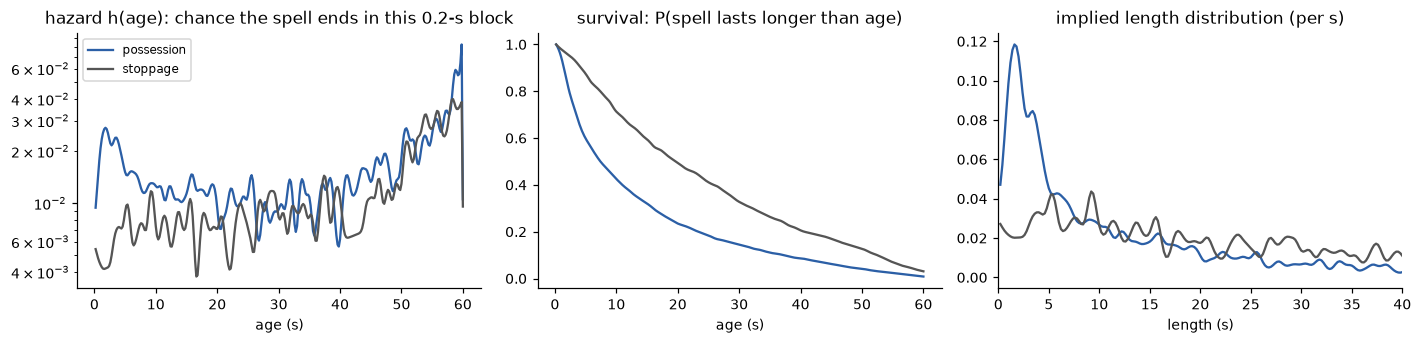

In [17]:
step_s = hsmm.STEP / 25
ages = np.arange(hsmm.N_AGE) * step_s + step_s
hz = {k: np.exp(prior[k + "_hazard"][0]) for k in ("team", "dead")}
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for k, c in (("team", COL[pm.H]), ("dead", "#555")):
    h = hz[k]; surv = np.r_[1, np.cumprod(1 - h)[:-1]]; pmf = surv * h
    ax[0].plot(ages, h, c=c, label="possession" if k == "team" else "stoppage")
    ax[1].plot(ages, surv, c=c); ax[2].plot(ages, pmf / step_s, c=c)
    print("{:10s} median length {:.1f} s, mean {:.1f} s".format("possession" if k == "team" else "stoppage", ages[np.searchsorted(-surv, -0.5)], (surv * step_s).sum()))
ax[0].set(title="hazard h(age): chance the spell ends in this 0.2-s block", xlabel="age (s)", yscale="log"); ax[0].legend(fontsize=8)
ax[1].set(title="survival: P(spell lasts longer than age)", xlabel="age (s)")
ax[2].set(title="implied length distribution (per s)", xlabel="length (s)", xlim=(0, 40))
plt.tight_layout(); plt.show()

**How the prior was set (all fitted, nothing hand-tuned per match).** Lengths are counted in 0.2-s
blocks, histogrammed, smoothed (Gaussian, 2 blocks) with a pseudo-count of 0.5 per age bin so no
length is impossible, and turned into hazards up to 60 s; beyond that a constant tail hazard
(`hsmm.py`: `STEP`, `SMOOTH_BLOCKS`, `PSEUDO`, `MAX_AGE_S`). Metrica's labels are used because their
spell lengths come from a full event log of the match.

**Temperature `(T_team, T_dead) = (2, 8)`.** Frames are not independent (25 per second, smoothed
features), so raw per-frame log-probabilities would overwhelm the prior. The emission is split into
"which team, if alive" and "dead or alive", and each part is divided by its own temperature
(`hsmm.tempered`). Chosen by leave-one-match-out on the Metrica matches (v4); the dead part needs much
more damping because P(D) is smooth over many seconds.

**Best path (MAP).** Viterbi over the blocks (`decoder.viterbi_segments`). **Samples.** Forward filtering,
backward sampling gives 3 × 40 alternative timelines (`decoder.posterior`), with a bias of 0, 1.5 and 3.0
towards shorter possessions (`SAMPLE_SETS`), so the pool also holds the short spells the MAP smooths away.

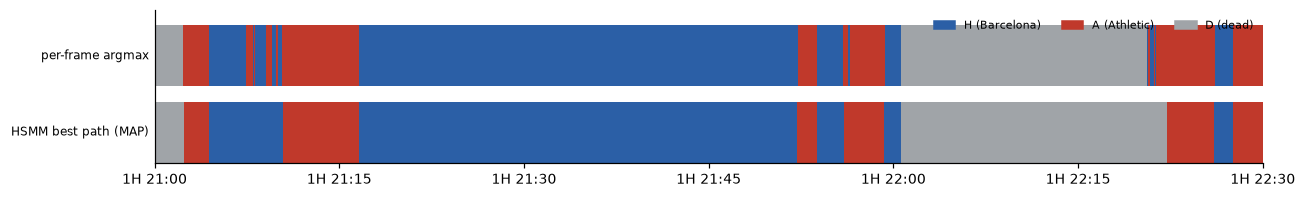

,possessions / min,D share
argmax,11.954,0.421
map,2.710,0.454
rescorer,2.521,0.478
final,2.521,0.478


In [18]:
fig, ax = plt.subplots(figsize=(13, 1.8))
ribbon(ax, B["codes"]["argmax"], W0, W1, 1, label="per-frame argmax"); ribbon(ax, B["codes"]["map"], W0, W1, 0, label="HSMM best path (MAP)")
ax.set_ylim(0, 2); ax.set_yticks([]); time_axis(ax, W0, W1); legend(ax); plt.show()
st = pd.DataFrame({k: {"possessions / min": len(dm.team_spells(dm.code_segments(c, runs))) / (g.sum() / 1500),
                       "D share": (c[g] == pm.D).mean()} for k, c in B["codes"].items()}).T
st

### The MAP and the top 5 candidates around one of its possessions

The candidate pool = every distinct possession in the MAP and the 120 samples, plus cuts at the switch
head's peaks (section 5). Each candidate gets a score **q** from the rescorer (section 6): its
predicted overlap with a real possession. Below: one MAP possession in the window, and the five
overlapping candidates of the same team with the highest q (shaded: the MAP possession).

MAP possession: H 1H 21:04 -> 1H 21:10 (6.0 s); 166 candidates overlap it


,start,length (s),team,q,kept,IoU with MAP,share of unbiased samples (s0_q),only from switch peaks
candidate,,,,,,,,
3334,1H 21:08,42.56,H,0.946,False,0.791,1.00,1
3330,1H 21:08,42.84,H,0.940,False,0.786,1.00,1
3335,1H 21:08,43.12,H,0.937,False,0.804,1.00,1
3241,1H 21:04,3.40,H,0.631,False,0.469,0.53,0
3235,1H 21:03,3.68,H,0.631,False,0.458,0.50,1


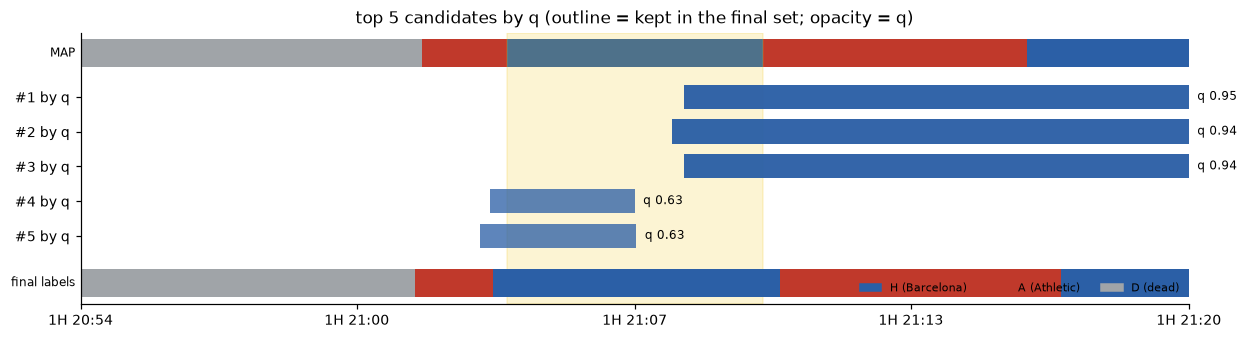

In [19]:
cands, q, chosen = B["cands"], B["q"], B["chosen"]
CX = B["cand_X"]
msp = dm.team_spells(B["map_segs"]); msp = msp[(msp[:, 0] >= W0) & (msp[:, 1] <= W1)]
ov = lambda s: np.flatnonzero((cands[:, 0] < s[1]) & (cands[:, 1] > s[0]))
target = msp[np.argmax([len(ov(s)) for s in msp])]
o = ov(target); o = o[cands[o, 2] == target[2]]; o = o[np.argsort(-q[o])][:5]
top5 = pd.DataFrame({"start": [fmt_t(c) for c in cands[o, 0]], "length (s)": (cands[o, 1] - cands[o, 0]) / 25,
                     "team": ["HAD"[c] for c in cands[o, 2]], "q": q[o], "kept": np.isin(o, chosen),
                     "IoU with MAP": CX["map_iou"].to_numpy()[o], "share of unbiased samples (s0_q)": CX["s0_q"].to_numpy()[o],
                     "only from switch peaks": CX["from_peaks"].to_numpy()[o].astype(int)}, index=pd.Index(o, name="candidate"))
print("MAP possession: {} {} -> {} ({:.1f} s); {} candidates overlap it".format("HAD"[target[2]], fmt_t(target[0]), fmt_t(target[1]), (target[1] - target[0]) / 25, len(ov(target))))
display(top5)
a, b = target[0] - 250, target[1] + 250
fig, ax = plt.subplots(figsize=(13, 3.2))
ribbon(ax, B["codes"]["map"], a, b, 6.2, label="MAP")
ax.axvspan(target[0], target[1], color="#f1c40f", alpha=0.18, label="the MAP possession")
for i, j in enumerate(o):
    s, e, c = cands[j]; ax.add_patch(mp.Rectangle((s, 5 - i), e - s, 0.7, fc=COL[c], ec="k" if j in chosen else "none", lw=1.2, alpha=0.35 + 0.65 * q[j]))
    ax.text(min(e, b) + 5, 5.35 - i, "q {:.2f}{}".format(q[j], "  kept" if j in chosen else ""), fontsize=8, va="center")
ribbon(ax, final, a, b, -0.4, label="final labels")
ax.set_ylim(-0.6, 7.2); ax.set_yticks([5.35 - i for i in range(len(o))]); ax.set_yticklabels(["#{} by q".format(i + 1) for i in range(len(o))])
time_axis(ax, a, b, 5); legend(ax, "lower right"); ax.set_title("top 5 candidates by q (outline = kept in the final set; opacity = q)"); plt.show()

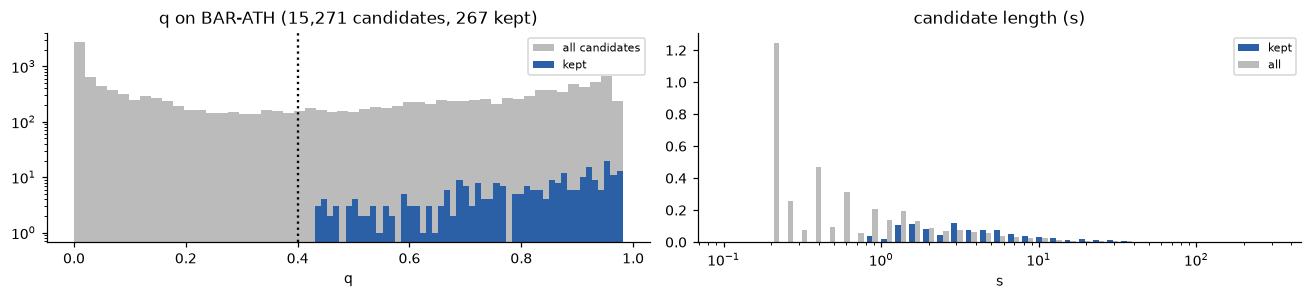

In [20]:
# the distribution of q over the whole pool on BAR-ATH, and what gets kept
fig, ax = plt.subplots(1, 2, figsize=(12, 2.8))
ax[0].hist(q, bins=50, color="#bbb", label="all candidates"); ax[0].hist(q[chosen], bins=50, color="#2b5fa6", label="kept")
ax[0].axvline(pl.LAMBDA, c="k", ls=":"); ax[0].set(title="q on BAR-ATH ({:,} candidates, {:,} kept)".format(len(q), len(chosen)), xlabel="q", yscale="log"); ax[0].legend(fontsize=7)
L = (cands[:, 1] - cands[:, 0]) / 25
ax[1].hist([L[chosen], L], bins=np.logspace(-1, 2.5, 40), color=["#2b5fa6", "#bbb"], label=["kept", "all"], density=True)
ax[1].set(xscale="log", title="candidate length (s)", xlabel="s"); ax[1].legend(fontsize=7); plt.tight_layout(); plt.show()

---
## 5. Switch head: P(possession changes within 0.5 s)

| | |
|---|---|
| model file | [`models/switch_head.txt`](../models/switch_head.txt), its columns in [`models/columns.json`](../models/columns.json) |
| trained by | `training.switch_table` → `training.fit_switch` (tables cached as `data/training/r1.0/switch_table_*.pkl`) |
| target | 1 if the possessing team changes within ±12 frames (`turnover.switch_target`; `H → short D → A` counts) |
| inputs | the 108 frame columns minus the interactions, plus **40 before-vs-after columns** (`to_*`: `ctrl`, `near_team`, `d_margin`… in the 12/25 frames before vs after, flips, free-flight runs) |
| parameters | `HEAD_PARAMS`, **300 trees** (1,500 trees raised AP by 0.014 but changed nothing after the rescorer) |

It does not decode anything itself. It (a) proposes extra candidates: each peak ≥ **0.2**, ≥ 6 frames
apart, cuts the MAP into new possible possessions (`peaks.py`), and (b) gives the rescorer and boundary
model 12+ columns about switches at a candidate's ends.

85,245 rows in this table (Metrica match 1), 4.5% positive


,target: switch?,to_ball_turn,to_ball_dspeed,speed_all_c3,ctrl_c3,h_spread_y,ball_speed_c1,a_spread_y,to_ctrl_flip25,P(switch)
72607,1,3.10,36.85,2.24,0.41,11.17,13.23,5.31,0.0,0.78
70352,1,2.52,16.99,1.88,0.11,10.51,8.10,9.35,0.0,0.74
61969,1,0.46,9.61,4.02,0.55,16.38,9.38,10.85,0.0,0.15
38651,0,0.31,0.84,1.92,0.65,14.23,2.77,10.30,0.0,0.00
67280,0,0.00,NaN,2.06,NaN,15.01,NaN,11.04,0.0,0.05
28100,0,0.00,0.17,1.32,1.00,15.58,1.28,13.08,0.0,0.00


,gain share,mean |contribution| on BAR-ATH (log-odds),kind,meaning
to_ball_turn,0.195,0.248,rad,largest change of ball direction within ±10 fr...
to_ball_dspeed,0.099,0.188,m/s,largest change of ball speed within ±10 frames
speed_all_c3,0.056,0.650,m/s,mean speed of all tracked players (play stops ...
ctrl_c3,0.041,0.097,−1 / 0 / +1,"+1 a home player within 1.0 m and closest, −1 ..."
h_spread_y,0.029,0.145,m,home spread across the pitch (std of y)
ball_speed_c1,0.027,0.446,m/s,"ball speed, 5-frame smoothed — mean over ±1 s"
a_spread_y,0.027,0.107,m,away spread across the pitch (std of y)
to_ctrl_flip25,0.026,0.019,flag 0/1,1 if ctrl changes sign between the 25 frames b...
to_near_since,0.021,0.074,frames,frames since the nearest team (sign of d_margi...
ctrl_past3,0.020,0.072,−1 / 0 / +1,"+1 a home player within 1.0 m and closest, −1 ..."


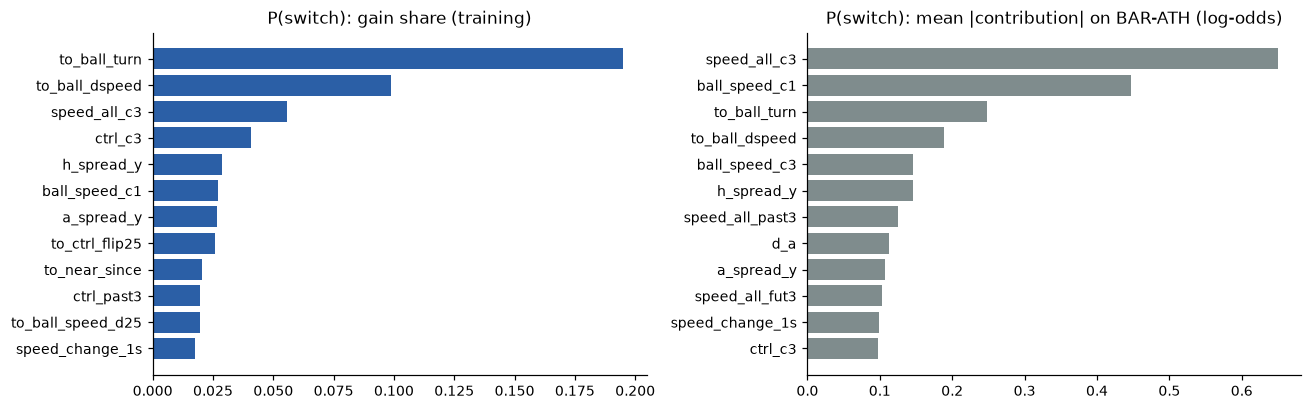

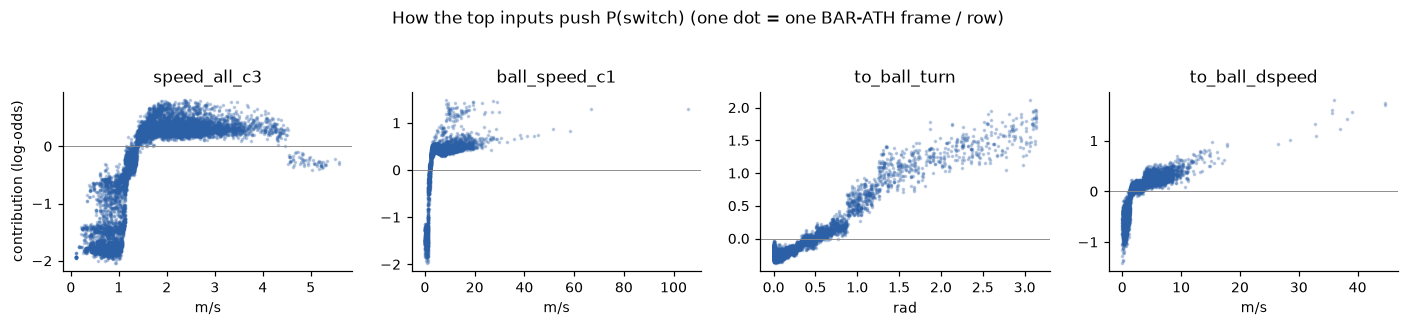

In [21]:
S = pd.read_pickle(os.path.join(possession.DATA_DIR, "training", "r1.0", "switch_table_metrica_1.pkl"))
scol = models["switch_cols"]
gsw = gain(models["switch"], 8).index
pick = np.r_[rng.choice(np.flatnonzero(S._y == 1), 3, False), rng.choice(np.flatnonzero(S._y == 0), 3, False)]
sm = S.iloc[pick][list(gsw)].copy(); sm.insert(0, "target: switch?", S._y.to_numpy()[pick]); sm["P(switch)"] = models["switch"].predict(S.iloc[pick][scol])
print("{:,} rows in this table (Metrica match 1), {:.1%} positive".format(len(S), S._y.mean())); display(sm.round(2)); del S
display(features_table(models["switch"], B["contrib"]["switch"], 12))
impact_plots(models["switch"], B["contrib"]["switch"], "P(switch)")

,frames,base rate,AUC,AP,AP / base rate
Metrica,5.099e+05,0.045,0.938,0.574,12.787
DFL,1.203e+06,0.054,0.922,0.448,8.241
all,1.713e+06,0.052,0.927,0.486,9.440


held out: the head finds switches at several times their base rate (a 'nearest team flips' rule had AP 0.09)


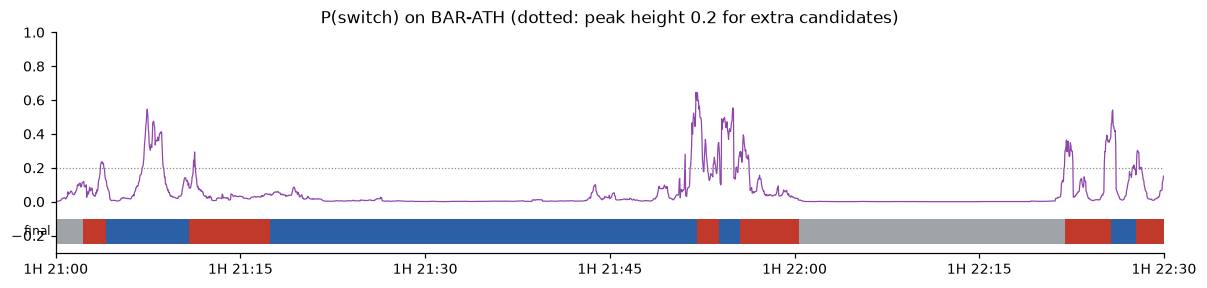

In [22]:
sw = H["switch"]
rows = {}
for s, d in (("Metrica", sw[sw.source == "metrica"]), ("DFL", sw[sw.source == "dfl"]), ("all", sw)):
    rows[s] = {"frames": len(d), "base rate": d.y.mean(), "AUC": roc_auc_score(d.y, d.p), "AP": average_precision_score(d.y, d.p),
               "AP / base rate": average_precision_score(d.y, d.p) / d.y.mean()}
display(pd.DataFrame(rows).T)
print("held out: the head finds switches at several times their base rate (a 'nearest team flips' rule had AP 0.09)")
fig, ax = plt.subplots(figsize=(13, 2.6)); x = np.arange(W0, W1)
ax.plot(x, B["p_switch"][W0:W1], c="#8e44ad", lw=0.8); ax.axhline(0.2, c="#888", ls=":", lw=0.8)
ribbon(ax, final, W0, W1, -0.25, h=0.15, label="final"); ax.set_ylim(-0.3, 1); time_axis(ax, W0, W1); ax.set_title("P(switch) on BAR-ATH (dotted: peak height 0.2 for extra candidates)"); plt.show()

---
## 6. Rescorer: q = how well a candidate matches a real possession

| | |
|---|---|
| model file | [`models/rescorer.txt`](../models/rescorer.txt), columns in `models/columns.json` |
| trained by | `training.candidate_rows` → `training.fit_rescorer` |
| one row | a candidate possession from a **held-out decode** of an external copy (decoded by heads trained without its match, so its mistakes are realistic) |
| target y | share of the IoU thresholds 0.3, 0.4, 0.5, 0.6, 0.7 at which the candidate overlaps a real same-team possession: exactly what spellF1 rewards |
| parameters | `RESCORER_PARAMS`: cross-entropy, lr 0.03, 31 leaves; 700 trees |

**Choosing the set** (`pipeline.choose`): among non-overlapping candidates, keep the set maximising
Σ (q − **λ**), λ = **0.4**; gaps are filled from the MAP. λ is a price per possession: a candidate is
worth keeping only if its expected credit beats it. Chosen on held-out dev copies (seeds 888/999):
0.35 and 0.4 tie, 0.4 kept fewer short spurious spells (v8).

84 inputs in five families: evidence inside and around the candidate (`p_team_*`, `p_dead_*`, `lo_*`),
agreement with the MAP (`map_*`), support in the three sample sets (`s0_*`, `s1_*`, `s2_*`), its
overlapping rivals (`s*_same_*`, `s*_other_*`), and the switch head at its ends (`sw_*`).

,gain share,mean |contribution| on BAR-ATH (log-odds),kind,meaning
s0_p30,0.303,0.330,share 0–1,share of samples with a same-team spell at IoU...
s1_iou_mean,0.089,0.401,share 0–1,mean best IoU with a same-team spell across sa...
s1_p30,0.086,0.140,share 0–1,share of samples with a same-team spell at IoU...
s2_p30,0.082,0.115,share 0–1,share of samples with a same-team spell at IoU...
entropy_in,0.048,0.255,nats,mean entropy of the H/A/D emission inside the ...
s1_q,0.047,0.144,share 0–1,mean over IoU 0.3–0.7 of the share of samples ...
s2_q,0.034,0.097,share 0–1,mean over IoU 0.3–0.7 of the share of samples ...
log_dur,0.034,0.643,log frames,log of the candidate's length
s0_q,0.026,0.114,share 0–1,mean over IoU 0.3–0.7 of the share of samples ...
s0_iou_mean,0.021,0.040,share 0–1,mean best IoU with a same-team spell across sa...


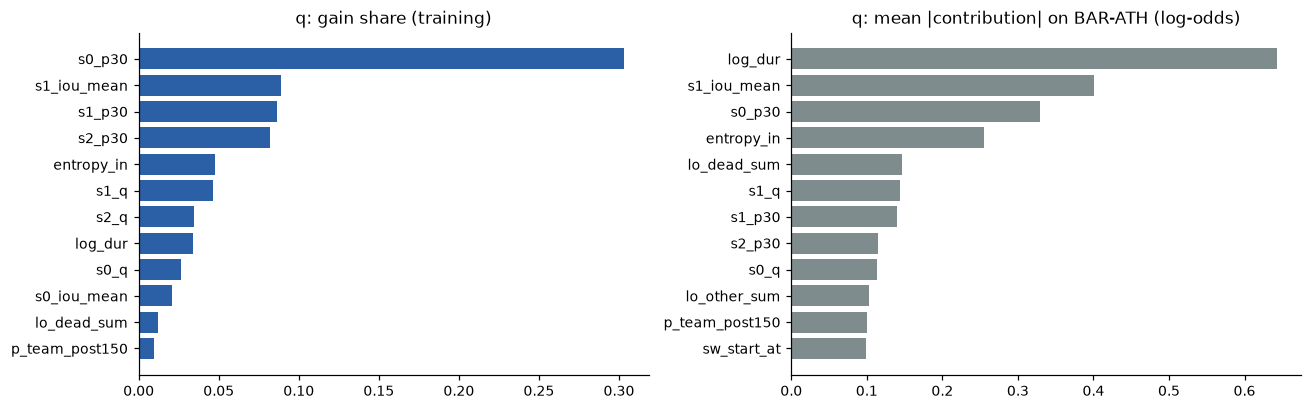

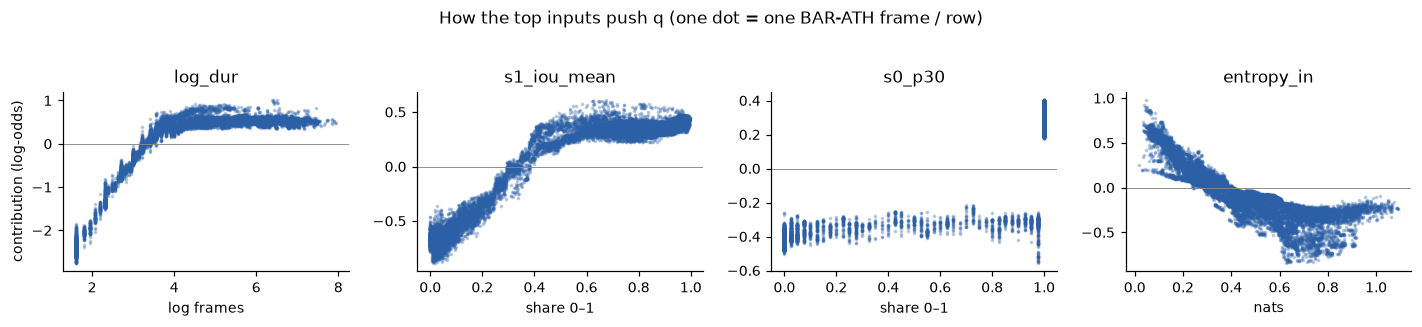

In [23]:
rc = H["rescorer_cols"]
qq = H["q"]
display(features_table(models["rescorer"], B["contrib"]["rescorer"], 15))
impact_plots(models["rescorer"], B["contrib"]["rescorer"], "q")

Sample rows (BAR-ATH candidates; features are model inputs, there is no target on BAR-ATH):


,log_dur,map_iou,s0_q,s2_q,p_team_in,lo_other_min5,sw_start,sw_end,sw_in_max,from_peaks,q
3334,6.970,0.791,1.00,1.000,0.823,-6.574,0.413,0.282,0.294,1.0,0.946
3330,6.976,0.786,1.00,1.000,0.823,-6.574,0.475,0.282,0.294,1.0,0.940
3335,6.983,0.804,1.00,1.000,0.824,-6.574,0.413,0.646,0.294,1.0,0.937
3241,4.443,0.469,0.53,0.985,0.759,-0.893,0.236,0.547,0.056,0.0,0.631
3235,4.522,0.458,0.50,0.980,0.720,-1.347,0.236,0.547,0.062,1.0,0.631


Held out (each match scored by a rescorer trained on the other 9 matches' dev copies):


,candidates,share y > 0,MAE,MAE of a constant,Pearson r,AUC (y > 0),mean y of kept
Metrica,244645.0,0.606,0.163,0.421,0.827,0.945,0.798
DFL,692082.0,0.580,0.174,0.403,0.804,0.941,0.760
all,936727.0,0.587,0.171,0.409,0.811,0.942,0.771


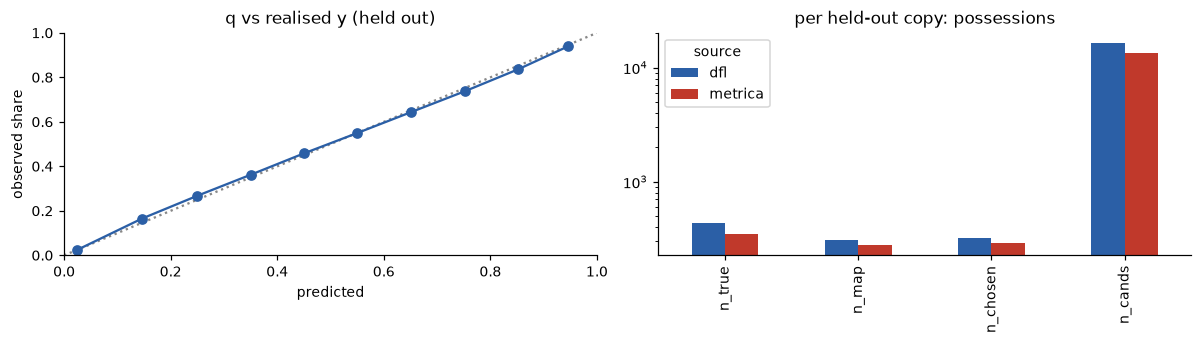

In [24]:
print("Sample rows (BAR-ATH candidates; features are model inputs, there is no target on BAR-ATH):")
smp = CX.iloc[o][["log_dur", "map_iou", "s0_q", "s2_q", "p_team_in", "lo_other_min5", "sw_start", "sw_end", "sw_in_max", "from_peaks"]].copy()
smp["q"] = q[o]; display(smp.round(3))
rows = {}
for s, d in (("Metrica", qq[qq.source == "metrica"]), ("DFL", qq[qq.source == "dfl"]), ("all", qq)):
    rows[s] = {"candidates": len(d), "share y > 0": (d.y > 0).mean(), "MAE": (d.q - d.y).abs().mean(),
               "MAE of a constant": (d.y.mean() - d.y).abs().mean(), "Pearson r": np.corrcoef(d.q, d.y)[0, 1],
               "AUC (y > 0)": roc_auc_score(d.y > 0, d.q), "mean y of kept": d.y[d.chosen].mean()}
print("Held out (each match scored by a rescorer trained on the other 9 matches' dev copies):")
display(pd.DataFrame(rows).T)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
reliability(ax[0], qq.y.to_numpy(), qq.q.to_numpy(), "q vs realised y (held out)")
per = pc.groupby("source")[["n_true", "n_map", "n_chosen", "n_cands"]].mean()
per.T.plot.bar(ax=ax[1], color=["#2b5fa6", "#c0392b"]); ax[1].set(title="per held-out copy: possessions", yscale="log"); plt.tight_layout(); plt.show()

---
## 7. Boundary model: moving each change of possession

| | |
|---|---|
| model file | [`models/boundary.txt`](../models/boundary.txt) |
| trained by | `training.boundary_table` → `training.fit_boundary` |
| one row | a label change in a held-out decode (after the rescorer) |
| target | frames from it to the nearest real change of the same kind (within 50 frames), clipped to ±25; 0 if none |
| inputs | 49: the change's kind, the emission log-odds new-vs-old, P(D), P(H), switch-head rank at 11 offsets (−25…+25), where the switch head peaks, lengths of the spells either side |
| parameters | `BOUNDARY_PARAMS`: Huber (α 10), lr 0.05, 15 leaves; 300 trees |

The predicted shift is rounded and applied, keeping at least 5 frames of each neighbour
(`BOUNDARY_CLIP` 25, `BOUNDARY_MIN_KEEP` 5).

,gain share,mean |contribution| on BAR-ATH (log-odds),kind,meaning
psw_peak_k,0.120,1.152,frames,where p_switch peaks within ±25 frames of the ...
psw_-15,0.075,0.562,rank 0–1,p_switch as its rank within the match 15 frame...
dll_0,0.053,0.392,log-odds,emission log-odds of the new label vs the old ...
dll_25,0.053,0.831,log-odds,emission log-odds of the new label vs the old ...
psw_15,0.048,0.453,rank 0–1,p_switch as its rank within the match 15 frame...
dll_-3,0.045,0.385,log-odds,emission log-odds of the new label vs the old ...
psw_-10,0.040,0.417,rank 0–1,p_switch as its rank within the match 10 frame...
kind,0.036,0.223,category,"boundary kind: 0 H>A, 1 A>H, 2 H>D, 3 A>D, 4 D..."
dll_-25,0.036,0.508,log-odds,emission log-odds of the new label vs the old ...
len_left,0.030,0.358,log frames,length of the spell on the left of the boundary


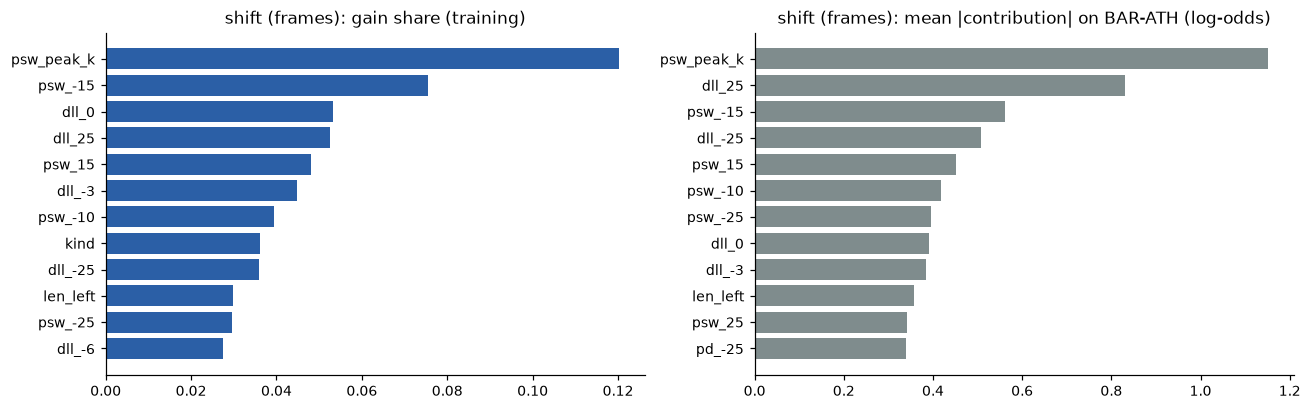

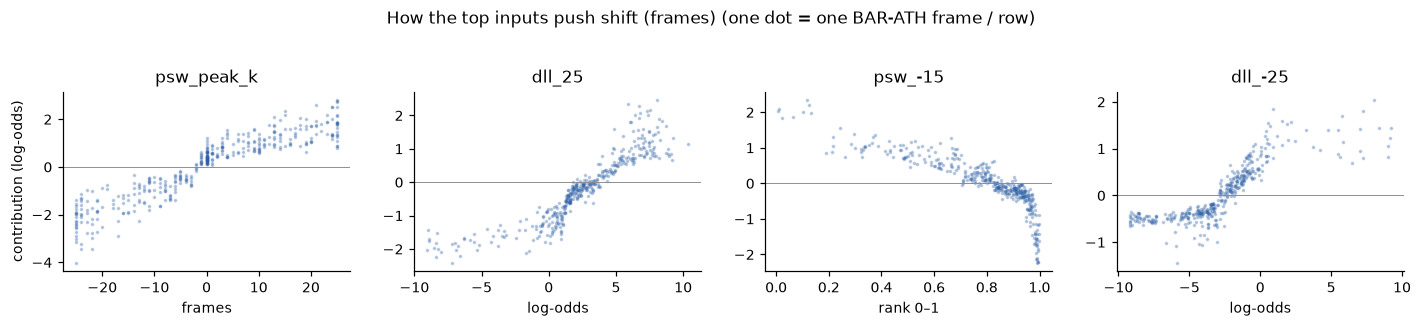

Held out (leave one match out): mean |frames to the real change|, matched changes only (70% of all)


,before,after,n
k,,,
A>D,10.52,8.77,1549.0
A>H,12.09,10.41,5008.0
D>A,6.83,5.80,2269.0
D>H,6.84,5.78,2335.0
H>A,11.95,10.60,4954.0
H>D,10.90,9.30,1720.0
all,10.44,9.02,17835.0


within 5 frames: 49.9% before -> 60.0% after


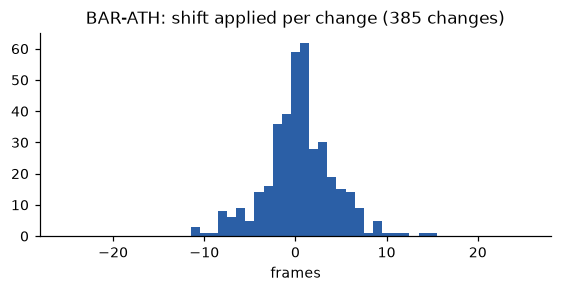

In [25]:
display(features_table(models["boundary"], B["contrib"]["boundary"], 12))
impact_plots(models["boundary"], B["contrib"]["boundary"], "shift (frames)")
bd = H["bound"]
kinds = {0: "H>A", 1: "A>H", 2: "H>D", 3: "A>D", 4: "D>H", 5: "D>A", 6: "other"}
m_ = bd.off.notna()
mv = np.round(bd.pred)
res = bd[m_].assign(before=lambda d: d.off.abs(), after=lambda d: (d.off - mv[m_]).abs(), k=lambda d: d.kind.map(kinds))
tab = res.groupby("k")[["before", "after"]].mean().assign(n=res.groupby("k").size())
tab.loc["all"] = [res.before.mean(), res.after.mean(), len(res)]
print("Held out (leave one match out): mean |frames to the real change|, matched changes only ({:.0%} of all)".format(m_.mean()))
display(tab.round(2))
print("within 5 frames: {:.1%} before -> {:.1%} after".format((res.before <= 5).mean(), (res.after <= 5).mean()))
sh = np.round(B["shift"]); fig, ax = plt.subplots(figsize=(6, 2.4))
ax.hist(np.clip(sh, -25, 25), bins=np.arange(-25.5, 26), color="#2b5fa6"); ax.set(title="BAR-ATH: shift applied per change ({:,} changes)".format(len(sh)), xlabel="frames"); plt.show()

---
## 8. End to end: what each stage is worth

spellF1 on every held-out copy (60 copies, 10 matches; each stage uses only models trained without the
copy's match). Seeds 888/999 were used to choose settings; **seed 777 is the confirmation set**.

argmax    map  rescorer  final
source  set                                          
dfl     777 (confirm)   0.292  0.617     0.644  0.650
        888/999 (dev)   0.287  0.610     0.640  0.645
metrica 777 (confirm)   0.380  0.688     0.731  0.738
        888/999 (dev)   0.371  0.679     0.724  0.730

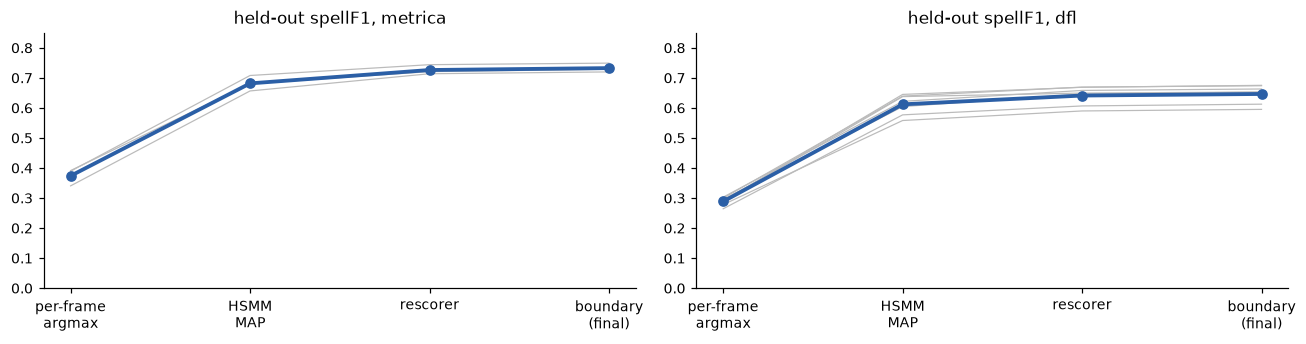

In [26]:
pc["set"] = np.where(pc.seed == 777, "777 (confirm)", "888/999 (dev)")
stages = ["argmax", "map", "rescorer", "final"]
tab = pc.groupby(["source", "set"])[stages].mean()
display(tab.round(4))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
for a, s in zip(ax, ("metrica", "dfl")):
    d = pc[pc.source == s]
    for mt, dd in d.groupby("match"):
        a.plot(range(4), dd[stages].mean().values, c="#bbb", lw=0.8)
    a.plot(range(4), d[stages].mean().values, c="#2b5fa6", lw=2.5, marker="o")
    a.set(xticks=range(4), xticklabels=["per-frame\nargmax", "HSMM\nMAP", "rescorer", "boundary\n(final)"], title="held-out spellF1, " + s, ylim=(0, 0.85))
plt.tight_layout(); plt.show()

BAR-ATH by stage (sanity statistics only, no labels):


,possessions / min,D share,H share,A share
argmax,11.954,0.421,0.348,0.231
map,2.710,0.454,0.333,0.213
rescorer,2.521,0.478,0.322,0.200
final,2.521,0.478,0.322,0.199


held-out truth: 4.58 possessions/min on DFL, 3.68 on Metrica


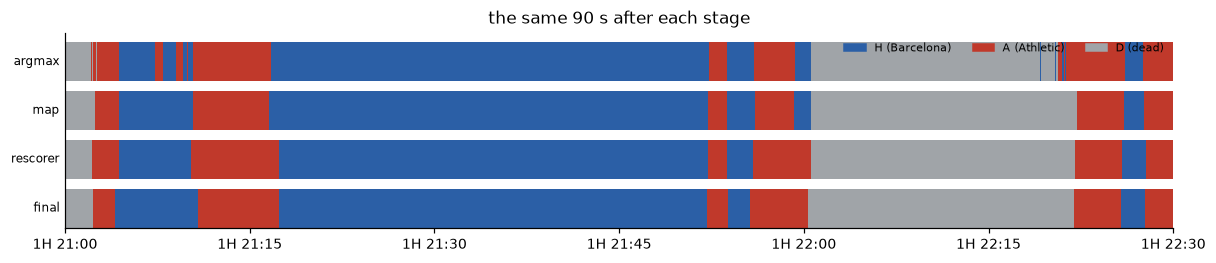

In [27]:
rate = pd.DataFrame({k: {"possessions / min": len(dm.team_spells(dm.code_segments(c, runs))) / (g.sum() / 1500),
                         "D share": (c[g] == pm.D).mean(), "H share": (c[g] == pm.H).mean(), "A share": (c[g] == pm.A).mean()}
                     for k, c in B["codes"].items()}).T
print("BAR-ATH by stage (sanity statistics only, no labels):")
display(rate.round(3))
print("held-out truth: {:.2f} possessions/min on DFL, {:.2f} on Metrica".format(
    (pc[pc.source == 'dfl'].n_true / pc[pc.source == 'dfl'].minutes).mean(), (pc[pc.source == 'metrica'].n_true / pc[pc.source == 'metrica'].minutes).mean()))
fig, ax = plt.subplots(figsize=(13, 2.3))
for i, k in enumerate(["argmax", "map", "rescorer", "final"]):
    ribbon(ax, B["codes"][k], W0, W1, 3 - i, label=k)
ax.set_ylim(0, 4); ax.set_yticks([]); time_axis(ax, W0, W1); legend(ax); ax.set_title("the same 90 s after each stage"); plt.show()

---
## 9. Every hand-picked constant

Everything not listed here is learned (LightGBM models, the HSMM prior) or derived (the whistle weight).

| constant | value | what it does | how it was chosen |
|---|---|---|---|
| `features.CONTROL_RADIUS` | 1.0 m | a player this close to the ball, and nearest, "controls" it (`ctrl`) | held-out external matches, 0.5–1.5 m grid (v12: +0.005 over 1.5 m) |
| `training.HEAD_ROUNDS` | 1,500 | trees in the dead / team heads | held-out log loss on DFL bottoms out at 800–1,800; spellF1 +0.013 over 300 (v13) |
| `training.HEAD_PARAMS` | lr 0.05, 31 leaves, 200 / leaf | head trees | defaults from v2, kept |
| `training.SHIFTED` | 8 columns dropped | interaction columns whose BAR-ATH distribution is outside the training matches' | input shift audit (no labels) |
| `pipeline.EPS` | 1e-4 | probability floor before logs | caps any single frame's evidence at log(1e-4) |
| `pipeline.TEMPERATURE` | (2, 8) | damping of team / dead evidence in the HSMM | leave-one-match-out on the Metrica matches (v4) |
| `pipeline.SET_PIECE_WEIGHT` | 3.0 per frame, 2 s | set-piece tag → D | 50 × 3 / T_dead = 18.8 > 12.8 the prior charges for a stoppage: near-certain |
| `pipeline.TAG_GAP_WEIGHT` | 0.6 per frame | untagged frame → D | half the measured log-likelihood ratio vs rule-based ball-out labels |
| `whistle.WHISTLE_SPAN` | 75 frames | evidence window after a stop whistle | 3 s, the length of a typical short stoppage |
| whistle weight | derived (above) | log-odds per frame after a stop whistle | `dead_insert_cost × T_dead / span`: the 3 s pay exactly for one inserted stoppage |
| `whistle.WHISTLES_PER_MATCH` | 34 | number of whistle events the detector threshold yields | mean whistled events per DFL match (DFL event data) |
| `whistle.WHISTLE_ALIVE_BEFORE` | 2 s, P(D) < 0.5 | a whistle counts as a *stop* only if play looked alive before it | rule (restart whistles are ignored) |
| `pipeline.SAMPLE_SETS` | 3 × 40 samples, bias 0 / 1.5 / 3.0 | sampled timelines for the candidate pool | pool oracle on held-out copies (v8) |
| `pipeline.PEAK_HEIGHT`, `peaks.MIN_DIST` | 0.2, 6 frames | switch-head peaks that cut extra candidates | pool oracle on held-out copies (v10: 0.708 → 0.766) |
| `pipeline.LAMBDA` | 0.4 | price per kept possession | held-out dev copies; 0.35 tied, 0.4 kept fewer spurious spells (v8) |
| `pipeline.BOUNDARY_CLIP`, `BOUNDARY_MIN_KEEP` | 25, 5 frames | max boundary move, min neighbour length | ±1 s covers the label timing noise (~±1 s); fixed |
| `hsmm.STEP`, `MAX_AGE_S`, `SMOOTH_BLOCKS`, `PSEUDO` | 0.2 s, 60 s, 2, 0.5 | resolution and smoothing of the duration model | fixed at v3; not tuned |
| `training.HEAD_COPIES`, `HEAD_STEP` | 3/2 copies, every 5th/10th frame | size of the training tables | memory on an 8 GB laptop |

In [28]:
from possession import features as F
consts = {"CONTROL_RADIUS": F.CONTROL_RADIUS,
          "HEAD_ROUNDS": tr.HEAD_ROUNDS, "SWITCH_ROUNDS": tr.SWITCH_ROUNDS, "RESCORER_ROUNDS": tr.RESCORER_ROUNDS,
          "BOUNDARY_ROUNDS": tr.BOUNDARY_ROUNDS, "TEMPERATURE": pl.TEMPERATURE, "SET_PIECE_WEIGHT": pl.SET_PIECE_WEIGHT,
          "TAG_GAP_WEIGHT": pl.TAG_GAP_WEIGHT, "WHISTLE_SPAN": WHISTLE_SPAN, "whistle weight": round(B["whistle_weight"], 3),
          "WHISTLES_PER_MATCH": WHISTLES_PER_MATCH, "SAMPLE_SETS": pl.SAMPLE_SETS, "PEAK_HEIGHT": pl.PEAK_HEIGHT,
          "LAMBDA": pl.LAMBDA, "BOUNDARY_CLIP": pl.BOUNDARY_CLIP, "BOUNDARY_MIN_KEEP": pl.BOUNDARY_MIN_KEEP, "EPS": pl.EPS}
print("values read from the code that made the submission:")
pd.Series({k: str(v) for k, v in consts.items()}, name="value").to_frame()

values read from the code that made the submission:


,value
CONTROL_RADIUS,1.0
HEAD_ROUNDS,1500
SWITCH_ROUNDS,300
RESCORER_ROUNDS,700
BOUNDARY_ROUNDS,300
TEMPERATURE,"(2, 8)"
SET_PIECE_WEIGHT,3.0
TAG_GAP_WEIGHT,0.6
WHISTLE_SPAN,75
whistle weight,1.367


---
### Summary

| stage | held-out evidence it works | BAR-ATH output |
|---|---|---|
| dead / team heads | see 2a / 2b tables (AUC, log loss, calibration per source) | P(D), P(H\|alive) per frame |
| evidence | whistle weight derived from the prior; tags rule-based | log-odds added on the frames in section 3 |
| HSMM | MAP lifts spellF1 far above per-frame argmax (section 8) | best path + 120 samples |
| switch head | AP several times the base rate (section 5) | extra candidates, rescorer features |
| rescorer | q calibrated against realised overlap; + spellF1 over MAP | chosen set of possessions |
| boundary | changes land closer to the real ones | final labels = submission |

The method and its history are in [`docs/technical_document.md`](../docs/technical_document.md).